# BT4012 · Experiment 2 V6 — Multi-Source LSTM, OOF Fusion & Historical Richness

**Research questions**  
**RQ1** Can a multi-source masked-attention LSTM improve standalone repayment-history prediction?  
**RQ2** Does its out-of-fold risk score add value beyond the teammate's **All Sources** GBDT and handcrafted temporal features?  
**RQ3** How does LSTM's incremental value vary with **observed months, number of historical loans, and installment-event density**?  
**RQ4 (exploratory)** Can **richness-aware conditional fusion** outperform a fixed blend?

**V6 changes vs V5:**  
1. **OOF uses last-hidden pooling** (`attention=False`): V5 showed last_hidden (0.600) substantially outperformed attention (0.564) standalone; OOF now uses the stronger variant.  
2. **Weighted BCE loss**: `pos_weight ≈ 11.5` addresses the ~8% default-rate class imbalance during LSTM training.  
3. **Multi-source handcrafted temporal features**: `make_temporal_features` now extracts trends from bureau balance DPD, POS DPD, and credit card utilisation channels (8 → 14 features).  
4. **Bureau balance flat aggregates** added to GBDT feature set: `bb_max_dpd`, `bb_months_with_dpd`, `bb_ever_late_share`.

Run top to bottom in Colab with GPU. All data live in `MyDrive/home_credit_bt4012/clean_data`.

In [44]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from sklearn.ensemble import HistGradientBoostingClassifier
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'

DATA_DIR=Path('/content/drive/MyDrive/home_credit_bt4012/clean_data')
assert DATA_DIR.exists(), f'Folder not found: {DATA_DIR}'
T=12
EPOCHS=24
PATIENCE=5
BATCH_SIZE=512
RUN_BILSTM=True
RUN_FLAT_MLP=True
OOF_FOLDS=3
OUTPUT_DIR=DATA_DIR.parent/'experiment2_outputs'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
print('Device:',DEVICE,'Clean data:',DATA_DIR)

RUN_LOAN_AWARE=True
RUN_ORDER_ABLATION=True


ModuleNotFoundError: No module named 'google'

In [45]:
# ── Local alternative (skip the Colab cell above and run this instead) ──
# Adjust LOCAL_ROOT to wherever the 'outputs' folder lives on your machine.

from pathlib import Path
import os, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from sklearn.ensemble import HistGradientBoostingClassifier
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

LOCAL_ROOT = Path(__file__).resolve().parent.parent if '__file__' in dir() else Path.cwd().parent
DATA_DIR = LOCAL_ROOT / 'clean_data'
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / 'clean_data'
assert DATA_DIR.exists(), f'clean_data not found. Set LOCAL_ROOT manually. Tried: {DATA_DIR}'

T = 12
EPOCHS = 24
PATIENCE = 5
BATCH_SIZE = 512
RUN_BILSTM = True
RUN_FLAT_MLP = True
OOF_FOLDS = 3
OUTPUT_DIR = DATA_DIR.parent / 'experiment2_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, ' Clean data:', DATA_DIR)

RUN_LOAN_AWARE = True
RUN_ORDER_ABLATION = True

Device: mps  Clean data: /Users/yichuan/Desktop/NUS/BT4012/BT4012 home credit/outputs/clean_data


## 1 · Shared clean data and canonical splits

In [46]:
CLEAN=DATA_DIR
required=['application.parquet','bureau.parquet','bureau_balance.parquet',
          'previous_application.parquet','installments.parquet',
          'credit_card.parquet','pos_cash.parquet','splits.csv']
missing=[x for x in required if not (CLEAN/x).exists()]
assert not missing, f'Missing in {CLEAN}: {missing}'
splits=pd.read_csv(CLEAN/'splits.csv')
assert {'SK_ID_CURR','TARGET','split'}.issubset(splits.columns)
splits['split']=splits['split'].str.lower().replace({'validation':'val','valid':'val'})
assert splits.SK_ID_CURR.is_unique
assert set(splits['split'])=={'train','val','test'}
app=pd.read_parquet(CLEAN/'application.parquet').drop(columns=['TARGET'],errors='ignore')
app=app.merge(splits[['SK_ID_CURR','TARGET','split']],on='SK_ID_CURR',how='inner',validate='one_to_one')
assert len(app)==len(splits)
ids=app.SK_ID_CURR.to_numpy(); y=app.TARGET.to_numpy(dtype='int64')
train_idx=np.flatnonzero(app['split'].eq('train'));val_idx=np.flatnonzero(app['split'].eq('val'));test_idx=np.flatnonzero(app['split'].eq('test'))
print('Split counts:',app['split'].value_counts().to_dict())

Split counts: {'train': 69999, 'val': 15001, 'test': 15000}


## 2 · Rebuild Experiment 1 All Sources feature matrix (same feature engineering)

In [47]:
# Bureau: loans at other lenders
b = pd.read_parquet(CLEAN / "bureau.parquet")
bureau = b.groupby("SK_ID_CURR").agg(
    n_bureau=("SK_ID_BUREAU", "size"),
    bureau_debt=("AMT_CREDIT_SUM_DEBT", "sum"),
    bureau_overdue=("AMT_CREDIT_SUM_OVERDUE", "sum"),
    bureau_credit=("AMT_CREDIT_SUM", "sum"),
)
bureau["bureau_debt_ratio"] = bureau["bureau_debt"] / bureau["bureau_credit"].where(bureau["bureau_credit"] > 0)

# Previous Home Credit applications (duplicate submissions removed)
p = pd.read_parquet(CLEAN / "previous_application.parquet")
p = p[p["IS_DUPLICATE_SUBMISSION"] == 0].copy()
p["refused"] = (p["NAME_CONTRACT_STATUS"].astype(str) == "Refused").astype(int)
prev = p.groupby("SK_ID_CURR").agg(
    n_prev=("SK_ID_PREV", "size"),
    prev_refusal_rate=("refused", "mean"),
    prev_amt_mean=("AMT_APPLICATION", "mean"),
)

# Instalments: one row per instalment (split payments already merged in cleaning)
i = pd.read_parquet(CLEAN / "installments.parquet")
paid = i["DAYS_ENTRY_PAYMENT"].notna()
i["late"] = np.where(paid, (i["DAYS_ENTRY_PAYMENT"] - i["DAYS_INSTALMENT"]) > 0, np.nan)   # unpaid: not counted
i["under"] = (i["AMT_INSTALMENT"] - i["AMT_PAYMENT"].fillna(0)).clip(lower=0)
inst = i.groupby("SK_ID_CURR").agg(
    n_inst=("SK_ID_PREV", "size"),
    late_rate=("late", "mean"),
    underpay_mean=("under", "mean"),
)

# Credit cards: utilisation
c = pd.read_parquet(CLEAN / "credit_card.parquet")
c["util"] = c["AMT_BALANCE"] / c["AMT_CREDIT_LIMIT_ACTUAL"].where(c["AMT_CREDIT_LIMIT_ACTUAL"] > 0)
cc = c.groupby("SK_ID_CURR").agg(cc_util_mean=("util", "mean"), cc_months=("MONTHS_BALANCE", "nunique"))

hist = bureau.join([prev, inst, cc], how="outer").reset_index()
hist_cols = [col for col in hist.columns if col != "SK_ID_CURR"]
print(f"History features: {len(hist_cols)} columns for {len(hist):,} applicants with any history")

History features: 13 columns for 99,277 applicants with any history


In [48]:
feat_old = app.merge(hist, on="SK_ID_CURR", how="left")
BUREAU = ["n_bureau", "bureau_debt", "bureau_overdue", "bureau_credit", "bureau_debt_ratio"]
PREVIOUS = ["n_prev", "prev_refusal_rate", "prev_amt_mean"]
REPAYMENT = ["n_inst", "late_rate", "underpay_mean", "cc_util_mean", "cc_months"]
assert set(BUREAU + PREVIOUS + REPAYMENT) == set(hist_cols)

In [49]:
# POS / cash loans
q = pd.read_parquet(CLEAN / "pos_cash.parquet", columns=["SK_ID_CURR", "SK_DPD", "CNT_INSTALMENT_FUTURE"])
q["dpd_flag"] = (q["SK_DPD"] > 0).astype("int32")
pos = q.groupby("SK_ID_CURR").agg(
    pos_max_dpd=("SK_DPD", "max"),
    pos_months_dpd=("dpd_flag", "sum"),
    pos_remaining_inst=("CNT_INSTALMENT_FUTURE", "mean"),
)

# Credit card, month by month (one row per applicant-month, summed over contracts)
c = pd.read_parquet(CLEAN / "credit_card.parquet", columns=[
    "SK_ID_CURR", "MONTHS_BALANCE", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL",
    "AMT_INST_MIN_REGULARITY", "AMT_PAYMENT_TOTAL_CURRENT", "SK_DPD"])
c["below_min"] = ((c["AMT_INST_MIN_REGULARITY"] > 0) &
                  (c["AMT_PAYMENT_TOTAL_CURRENT"].fillna(0) < c["AMT_INST_MIN_REGULARITY"])).astype("int32")
c["dpd_flag"] = (c["SK_DPD"] > 0).astype("int32")
c["min_ratio"] = c["AMT_PAYMENT_TOTAL_CURRENT"] / c["AMT_INST_MIN_REGULARITY"].where(c["AMT_INST_MIN_REGULARITY"] > 0)
m = c.groupby(["SK_ID_CURR", "MONTHS_BALANCE"], as_index=False).agg(
    bal=("AMT_BALANCE", "sum"), lim=("AMT_CREDIT_LIMIT_ACTUAL", "sum"),
    below=("below_min", "max"), dpd=("dpd_flag", "max"), min_ratio=("min_ratio", "mean"))
m["util"] = m["bal"] / m["lim"].where(m["lim"] > 0)
recent = m[m["MONTHS_BALANCE"] >= -3].groupby("SK_ID_CURR")["util"].mean()
card = m.groupby("SK_ID_CURR").agg(
    cc_months_below_min=("below", "sum"),
    cc_months_dpd=("dpd", "sum"),
    cc_min_ratio_mean=("min_ratio", "mean"),
    cc_util_overall=("util", "mean"),
)
card["cc_balance_trend"] = recent.reindex(card.index) - card["cc_util_overall"]
card = card.drop(columns="cc_util_overall")

# Instalments
i = pd.read_parquet(CLEAN / "installments.parquet", columns=[
    "SK_ID_CURR", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"])
paid = i["DAYS_ENTRY_PAYMENT"].notna()
i["days_late"] = np.where(paid, (i["DAYS_ENTRY_PAYMENT"] - i["DAYS_INSTALMENT"]).clip(lower=0), np.nan)
i["under_flag"] = ((i["AMT_INSTALMENT"] - i["AMT_PAYMENT"].fillna(0)) > 1.0).astype("int32")
i["paid_amt"] = i["AMT_PAYMENT"].fillna(0)
inst_new = i.groupby("SK_ID_CURR").agg(
    inst_max_days_late=("days_late", "max"),
    inst_mean_days_late=("days_late", "mean"),
    inst_underpay_freq=("under_flag", "mean"),
    paid_sum=("paid_amt", "sum"),
    due_sum=("AMT_INSTALMENT", "sum"),
)
inst_new["inst_paid_to_due"] = inst_new["paid_sum"] / inst_new["due_sum"].where(inst_new["due_sum"] > 0)
inst_new = inst_new.drop(columns=["paid_sum", "due_sum"])

# Bureau (loan-level)
b = pd.read_parquet(CLEAN / "bureau.parquet", columns=["SK_ID_CURR", "CREDIT_DAY_OVERDUE", "CREDIT_ACTIVE"])
bureau_new = b.groupby("SK_ID_CURR").agg(
    bureau_max_days_overdue=("CREDIT_DAY_OVERDUE", "max"),
    bureau_active_count=("CREDIT_ACTIVE", lambda s: (s.astype(str) == "Active").sum()),
)

# V6: Bureau balance flat aggregates (monthly DPD from external lenders)
bb_flat = pd.read_parquet(CLEAN / "bureau_balance.parquet", columns=["SK_ID_CURR", "STATUS_DPD"])
bb_flat["dpd_flag"] = (bb_flat["STATUS_DPD"].fillna(0) > 0).astype("int32")
bb_agg = bb_flat.groupby("SK_ID_CURR").agg(
    bb_max_dpd=("STATUS_DPD", "max"),
    bb_months_with_dpd=("dpd_flag", "sum"),
    bb_ever_late_share=("dpd_flag", "mean"),
)
print(f"Bureau balance flat: {len(bb_agg):,} applicants")

# Previous applications
p = pd.read_parquet(CLEAN / "previous_application.parquet", columns=[
    "SK_ID_CURR", "NAME_CONTRACT_STATUS", "DAYS_DECISION", "IS_DUPLICATE_SUBMISSION"])
p = p[p["IS_DUPLICATE_SUBMISSION"] == 0].copy()
p["approved"] = (p["NAME_CONTRACT_STATUS"].astype(str) == "Approved").astype("int32")
p["last_year"] = (p["DAYS_DECISION"] >= -365).astype("int32")
prev_new = p.groupby("SK_ID_CURR").agg(prev_approval_rate=("approved", "mean"), prev_apps_last_year=("last_year", "sum"))

new_hist = pos.join([card, inst_new, bureau_new, bb_agg, prev_new], how="outer").reset_index()
NEW_POS = ["pos_max_dpd", "pos_months_dpd", "pos_remaining_inst"]
NEW_CARD = ["cc_months_below_min", "cc_months_dpd", "cc_min_ratio_mean", "cc_balance_trend"]
NEW_INST = ["inst_max_days_late", "inst_mean_days_late", "inst_underpay_freq", "inst_paid_to_due"]
NEW_BUREAU = ["bureau_max_days_overdue", "bureau_active_count"]
NEW_BB = ["bb_max_dpd", "bb_months_with_dpd", "bb_ever_late_share"]
NEW_PREV = ["prev_approval_rate", "prev_apps_last_year"]
assert set(NEW_POS + NEW_CARD + NEW_INST + NEW_BUREAU + NEW_BB + NEW_PREV) == set(new_hist.columns) - {"SK_ID_CURR"}
print(f"New features: {len(new_hist.columns) - 1} columns for {len(new_hist):,} applicants")
display(new_hist.describe().T[["count", "mean", "min", "max"]].round(3))

Bureau balance flat: 29,922 applicants
New features: 18 columns for 99,290 applicants


,count,mean,min,max
SK_ID_CURR,99290.0,277928.762,100011.00,456248.000
pos_max_dpd,94164.0,15.262,0.00,4231.000
pos_months_dpd,94164.0,0.885,0.00,120.000
pos_remaining_inst,94155.0,9.215,0.00,59.500
cc_months_below_min,28368.0,2.096,0.00,70.000
cc_months_dpd,28368.0,1.546,0.00,94.000
cc_min_ratio_mean,19351.0,34.067,0.00,471288.531
cc_balance_trend,21320.0,0.007,-0.97,2.767
inst_max_days_late,94873.0,18.639,0.00,2852.000
inst_mean_days_late,94873.0,1.282,0.00,2813.000


In [50]:
feat = feat_old.merge(new_hist, on="SK_ID_CURR", how="left")
assert feat["SK_ID_CURR"].is_unique

# Define the application column list by excluding metadata/target columns
app_cols = [col for col in app.columns if col not in ["SK_ID_CURR", "TARGET", "split"]]

GROUPS = {
    "Application": app_cols,
    "+ Bureau": app_cols + BUREAU + NEW_BUREAU + NEW_BB,
    "+ Previous": app_cols + PREVIOUS + NEW_PREV,
    "+ Repayment": app_cols + REPAYMENT + NEW_POS + NEW_CARD + NEW_INST,
    "All sources": app_cols + hist_cols + NEW_POS + NEW_CARD + NEW_INST + NEW_BUREAU + NEW_BB + NEW_PREV,
}

## 3 · Build multi-source monthly sequences (oldest → newest)

**V5:** The monthly tensor now fuses four data sources into a single timeline per customer:
- **Installments** (13 channels): DPD, late rate, payment ratio, loan-aware dispersion — same as V4.
- **Bureau balance** (5 channels): monthly DPD status of loans at *other* lenders — **new, previously unused**.
- **POS cash** (3 channels): monthly DPD and remaining obligations on POS/cash loans — **new for sequences**.
- **Credit card** (3 channels): monthly utilization, DPD, payment-to-minimum ratio — **new for sequences**.

All sources share the same 12-month window (`T=12`). Bureau balance and POS/credit-card tables use `MONTHS_BALANCE` directly; installments are mapped via `floor(-DAYS_INSTALMENT / 30)`. Customers with no records from any source get all-zero rows (observed mask = False).

In [51]:
position = pd.Series(np.arange(len(ids)), index=ids)

# ── 3a. Installment channels (same as V4) ──────────────────────────────────
i_seq = pd.read_parquet(CLEAN / 'installments.parquet')
need = ['SK_ID_CURR','SK_ID_PREV','DAYS_INSTALMENT','DAYS_ENTRY_PAYMENT','AMT_INSTALMENT','AMT_PAYMENT']
assert set(need).issubset(i_seq.columns)
i_seq = i_seq[i_seq.SK_ID_CURR.isin(ids) & i_seq.DAYS_INSTALMENT.notna() & (i_seq.DAYS_INSTALMENT <= 0)].copy()
paid_mask = i_seq.DAYS_ENTRY_PAYMENT.notna() & (i_seq.DAYS_ENTRY_PAYMENT <= 0)
i_seq['DPD'] = np.where(paid_mask, np.maximum(i_seq.DAYS_ENTRY_PAYMENT - i_seq.DAYS_INSTALMENT, 0), np.nan)
i_seq['LATE'] = np.where(paid_mask, (i_seq.DAYS_ENTRY_PAYMENT > i_seq.DAYS_INSTALMENT).astype(float), np.nan)
i_seq['PAY_RATIO'] = np.where(paid_mask, i_seq.AMT_PAYMENT / i_seq.AMT_INSTALMENT.where(i_seq.AMT_INSTALMENT > 0), np.nan)
i_seq['UNDER_RATIO'] = np.where(paid_mask, ((i_seq.AMT_INSTALMENT - i_seq.AMT_PAYMENT).clip(lower=0) / i_seq.AMT_INSTALMENT.where(i_seq.AMT_INSTALMENT > 0)), np.nan)
i_seq['AMOUNT_LOG'] = np.log1p(i_seq.AMT_INSTALMENT.clip(lower=0))
i_seq['MONTH_IDX'] = np.floor(-i_seq.DAYS_INSTALMENT / 30).astype('int32')
i_seq = i_seq[i_seq.MONTH_IDX.between(0, T - 1)].copy()

monthly_inst = i_seq.groupby(['SK_ID_CURR','MONTH_IDX'], sort=False).agg(
    DPD_MEAN=('DPD','mean'), DPD_MAX=('DPD','max'), LATE_RATE=('LATE','mean'),
    PAYMENT_RATIO=('PAY_RATIO','mean'), UNDERPAYMENT_RATIO=('UNDER_RATIO','mean'),
    AMOUNT_LOG=('AMOUNT_LOG','mean'), N_INSTALLMENTS=('SK_ID_PREV','size'),
    N_LOANS=('SK_ID_PREV','nunique'), N_PAID=('LATE','count')).reset_index()

loan_month = (i_seq.groupby(['SK_ID_CURR','MONTH_IDX','SK_ID_PREV'], sort=False)
              .agg(LOAN_DPD=('DPD','max'), LOAN_LATE=('LATE','max')).reset_index())
loan_month['LOAN_LATE_FLAG'] = (loan_month['LOAN_LATE'] > 0).astype('float32')
loan_month['LOAN_DPD_VALID'] = loan_month['LOAN_DPD'].notna().astype('float32')
loan_extra = (loan_month.groupby(['SK_ID_CURR','MONTH_IDX'], sort=False)
    .agg(LOAN_DPD_STD=('LOAN_DPD','std'), LOAN_DPD_MAX=('LOAN_DPD','max'),
         N_LATE_LOANS=('LOAN_LATE_FLAG','sum'), N_VALID_LOANS=('LOAN_DPD_VALID','sum')).reset_index())
loan_extra['LATE_LOAN_SHARE'] = loan_extra.N_LATE_LOANS / loan_extra.N_VALID_LOANS.replace(0, np.nan)
monthly_inst = monthly_inst.merge(loan_extra, on=['SK_ID_CURR','MONTH_IDX'], how='left', validate='one_to_one')

INST_COLS = ['DPD_MEAN','DPD_MAX','LATE_RATE','PAYMENT_RATIO','UNDERPAYMENT_RATIO',
             'AMOUNT_LOG','N_INSTALLMENTS','N_LOANS','N_PAID',
             'LOAN_DPD_STD','LOAN_DPD_MAX','N_LATE_LOANS','LATE_LOAN_SHARE']
print(f'Installment channels: {len(INST_COLS)}, customers with data: {monthly_inst.SK_ID_CURR.nunique():,}')

# ── 3b. Bureau balance channels (NEW — external lender monthly DPD) ────────
bb = pd.read_parquet(CLEAN / 'bureau_balance.parquet')
bb = bb[bb.SK_ID_CURR.isin(ids)].copy()
bb['MONTH_IDX'] = (-bb['MONTHS_BALANCE']).astype('int32')
bb = bb[bb.MONTH_IDX.between(0, T - 1)].copy()
bb['DPD_VALID'] = bb['STATUS_DPD'].notna().astype('float32')
bb['DPD_POS'] = (bb['STATUS_DPD'].fillna(0) > 0).astype('float32')

monthly_bb = bb.groupby(['SK_ID_CURR','MONTH_IDX'], sort=False).agg(
    BB_DPD_MEAN=('STATUS_DPD','mean'),
    BB_DPD_MAX=('STATUS_DPD','max'),
    BB_N_ACTIVE=('IS_CLOSED', lambda s: (s == 0).sum()),
    BB_LATE_SHARE=('DPD_POS', 'mean'),
    BB_N_LOANS=('SK_ID_BUREAU','nunique'),
).reset_index()

BB_COLS = ['BB_DPD_MEAN','BB_DPD_MAX','BB_N_ACTIVE','BB_LATE_SHARE','BB_N_LOANS']
print(f'Bureau balance channels: {len(BB_COLS)}, customers with data: {monthly_bb.SK_ID_CURR.nunique():,}')

# ── 3c. POS cash channels (NEW for sequences) ──────────────────────────────
pc = pd.read_parquet(CLEAN / 'pos_cash.parquet',
                     columns=['SK_ID_CURR','MONTHS_BALANCE','SK_DPD','CNT_INSTALMENT_FUTURE'])
pc = pc[pc.SK_ID_CURR.isin(ids)].copy()
pc['MONTH_IDX'] = (-pc['MONTHS_BALANCE']).astype('int32')
pc = pc[pc.MONTH_IDX.between(0, T - 1)].copy()

monthly_pos = pc.groupby(['SK_ID_CURR','MONTH_IDX'], sort=False).agg(
    POS_DPD_MEAN=('SK_DPD','mean'),
    POS_DPD_MAX=('SK_DPD','max'),
    POS_REMAINING=('CNT_INSTALMENT_FUTURE','mean'),
).reset_index()

POS_COLS = ['POS_DPD_MEAN','POS_DPD_MAX','POS_REMAINING']
print(f'POS cash channels: {len(POS_COLS)}, customers with data: {monthly_pos.SK_ID_CURR.nunique():,}')

# ── 3d. Credit card channels (NEW for sequences) ───────────────────────────
cc_raw = pd.read_parquet(CLEAN / 'credit_card.parquet',
    columns=['SK_ID_CURR','MONTHS_BALANCE','AMT_BALANCE','AMT_CREDIT_LIMIT_ACTUAL',
             'AMT_INST_MIN_REGULARITY','AMT_PAYMENT_TOTAL_CURRENT','SK_DPD'])
cc_raw = cc_raw[cc_raw.SK_ID_CURR.isin(ids)].copy()
cc_raw['MONTH_IDX'] = (-cc_raw['MONTHS_BALANCE']).astype('int32')
cc_raw = cc_raw[cc_raw.MONTH_IDX.between(0, T - 1)].copy()
cc_raw['UTIL'] = cc_raw['AMT_BALANCE'] / cc_raw['AMT_CREDIT_LIMIT_ACTUAL'].where(
    cc_raw['AMT_CREDIT_LIMIT_ACTUAL'] > 0)
cc_raw['PAY_MIN_RATIO'] = cc_raw['AMT_PAYMENT_TOTAL_CURRENT'] / cc_raw['AMT_INST_MIN_REGULARITY'].where(
    cc_raw['AMT_INST_MIN_REGULARITY'] > 0)

monthly_cc = cc_raw.groupby(['SK_ID_CURR','MONTH_IDX'], sort=False).agg(
    CC_UTIL=('UTIL','mean'),
    CC_DPD_MAX=('SK_DPD','max'),
    CC_PAY_MIN_RATIO=('PAY_MIN_RATIO','mean'),
).reset_index()

CC_COLS = ['CC_UTIL','CC_DPD_MAX','CC_PAY_MIN_RATIO']
print(f'Credit card channels: {len(CC_COLS)}, customers with data: {monthly_cc.SK_ID_CURR.nunique():,}')

# ── 3e. Merge all sources into unified monthly tensor ───────────────────────
SEQ_COLS = INST_COLS + BB_COLS + POS_COLS + CC_COLS
N_CH = len(SEQ_COLS)
seq = np.full((len(ids), T, N_CH), np.nan, dtype=np.float32)
observed = np.zeros((len(ids), T), dtype=bool)

def fill_tensor(monthly_df, col_names, col_offset):
    """Fill the appropriate channels in seq tensor from a monthly DataFrame."""
    valid = monthly_df[monthly_df.SK_ID_CURR.isin(ids)]
    r = position.loc[valid.SK_ID_CURR].to_numpy()
    t = T - 1 - valid.MONTH_IDX.to_numpy()
    vals = valid[col_names].to_numpy(dtype='float32')
    seq[r, t, col_offset:col_offset + len(col_names)] = vals
    observed[r, t] = True

off = 0
fill_tensor(monthly_inst, INST_COLS, off); off += len(INST_COLS)
fill_tensor(monthly_bb,   BB_COLS,   off); off += len(BB_COLS)
fill_tensor(monthly_pos,  POS_COLS,  off); off += len(POS_COLS)
fill_tensor(monthly_cc,   CC_COLS,   off); off += len(CC_COLS)

# ── 3f. Multi-source handcrafted temporal features (V6: expanded) ──────────
def make_temporal_features(seq_arr, obs_arr):
    n_feat = 14
    z = np.full((len(seq_arr), n_feat), np.nan, dtype='float32')
    dpd_idx = SEQ_COLS.index('DPD_MEAN')
    ratio_idx = SEQ_COLS.index('PAYMENT_RATIO')
    bb_dpd_idx = SEQ_COLS.index('BB_DPD_MEAN')
    pos_dpd_idx = SEQ_COLS.index('POS_DPD_MEAN')
    cc_util_idx = SEQ_COLS.index('CC_UTIL')
    ts = np.arange(T)
    for j in range(len(seq_arr)):
        dpd = seq_arr[j, :, dpd_idx]; ratio = seq_arr[j, :, ratio_idx]
        mask = obs_arr[j] & np.isfinite(dpd)
        if mask.sum():
            z[j,0] = np.mean(dpd[mask]); z[j,1] = np.std(dpd[mask])
            z[j,2] = np.polyfit(ts[mask], dpd[mask], 1)[0] if mask.sum() > 1 else np.nan
            recent = dpd[-3:]; earlier = dpd[:-3]
            if np.isfinite(recent).any() and np.isfinite(earlier).any():
                z[j,3] = np.nanmean(recent) - np.nanmean(earlier)
            late = (dpd > 0) & mask; streak = mx = 0
            for v in late: streak = streak + 1 if v else 0; mx = max(mx, streak)
            z[j,4] = mx
        good = obs_arr[j] & np.isfinite(ratio)
        if good.sum(): z[j,5] = np.std(ratio[good]); z[j,6] = np.mean(ratio[good])
        z[j,7] = obs_arr[j].sum()
        # V6: bureau balance DPD features
        bb_dpd = seq_arr[j, :, bb_dpd_idx]
        bb_mask = obs_arr[j] & np.isfinite(bb_dpd)
        if bb_mask.sum():
            z[j,8] = np.mean(bb_dpd[bb_mask])
            z[j,9] = np.polyfit(ts[bb_mask], bb_dpd[bb_mask], 1)[0] if bb_mask.sum() > 1 else np.nan
        # V6: POS DPD mean
        pos_dpd = seq_arr[j, :, pos_dpd_idx]
        pos_mask = obs_arr[j] & np.isfinite(pos_dpd)
        if pos_mask.sum():
            z[j,10] = np.mean(pos_dpd[pos_mask])
        # V6: credit card utilization features
        cc_util = seq_arr[j, :, cc_util_idx]
        cc_mask = obs_arr[j] & np.isfinite(cc_util)
        if cc_mask.sum():
            z[j,11] = np.mean(cc_util[cc_mask])
            z[j,12] = np.polyfit(ts[cc_mask], cc_util[cc_mask], 1)[0] if cc_mask.sum() > 1 else np.nan
        # V6: cross-source recent deterioration (all DPD channels)
        all_dpd = np.column_stack([
            seq_arr[j, :, dpd_idx], seq_arr[j, :, bb_dpd_idx], seq_arr[j, :, pos_dpd_idx]])
        row_valid = obs_arr[j] & np.any(np.isfinite(all_dpd), axis=1)
        if row_valid.sum() > 1:
            combined = np.nanmean(all_dpd, axis=1)
            r3 = combined[-3:]; e = combined[:-3]
            if np.isfinite(r3).any() and np.isfinite(e).any():
                z[j,13] = np.nanmean(r3) - np.nanmean(e)
    return pd.DataFrame(z, columns=[
        'TEMP_DPD_MEAN','TEMP_DPD_VOL','TEMP_DPD_TREND',
        'TEMP_RECENT_DETERIORATION','TEMP_MAX_LATE_STREAK','TEMP_PAYMENT_VOL',
        'TEMP_PAYMENT_MEAN','TEMP_OBS_MONTHS',
        'TEMP_BB_DPD_MEAN','TEMP_BB_DPD_TREND',
        'TEMP_POS_DPD_MEAN',
        'TEMP_CC_UTIL_MEAN','TEMP_CC_UTIL_TREND',
        'TEMP_CROSS_DETERIORATION'])

temporal = make_temporal_features(seq, observed)

no_hist = int((~observed.any(axis=1)).sum())
print(f'\nMulti-source monthly tensor: {seq.shape} ({N_CH} channels)')
print(f'Handcrafted temporal features: {temporal.shape[1]} (V5 had 8)')
print(f'Customers without ANY history: {no_hist} ({no_hist/len(ids)*100:.1f}%)')
print(f'(V4 had 29,419 with no history using installments only)')

Installment channels: 13, customers with data: 70,581
Bureau balance channels: 5, customers with data: 29,187
POS cash channels: 3, customers with data: 65,538
Credit card channels: 3, customers with data: 28,368


/var/folders/q2/3h5_22h15w37t121c6t3dfmw0000gn/T/ipykernel_49134/2213771921.py:162: RuntimeWarning: Mean of empty slice
  combined = np.nanmean(all_dpd, axis=1)



Multi-source monthly tensor: (100000, 12, 24) (24 channels)
Handcrafted temporal features: 14 (V5 had 8)
Customers without ANY history: 19093 (19.1%)
(V4 had 29,419 with no history using installments only)


## 4 · Train-only normalization; do not fit preprocessing on validation or test

In [52]:
seq_train = seq[train_idx][observed[train_idx]]
med = np.nanmedian(seq_train, axis=0); med = np.where(np.isfinite(med), med, 0).astype('float32')
filled = np.where(np.isfinite(seq_train), seq_train, med)
scaler = StandardScaler().fit(filled)
Xseq = np.where(np.isfinite(seq), seq, med.reshape(1, 1, -1))
Xseq = scaler.transform(Xseq.reshape(-1, N_CH)).reshape(seq.shape).astype('float32')
Xseq[~observed] = 0
Xseq = np.concatenate([Xseq, observed[..., None].astype('float32')], axis=-1)

# Aggregate same-window features for independent representation comparison.
agg = i_seq.groupby('SK_ID_CURR').agg(
    DPD_MEAN=('DPD','mean'), DPD_MAX=('DPD','max'), LATE_RATE=('LATE','mean'),
    PAY_RATIO=('PAY_RATIO','mean'), UNDER_RATIO=('UNDER_RATIO','mean'),
    AMOUNT_LOG=('AMOUNT_LOG','mean'), N_INST=('SK_ID_PREV','size'),
    N_LOANS=('SK_ID_PREV','nunique')).reindex(ids)
agg['OBS_MONTHS'] = observed.sum(axis=1)
agg['HAS_HISTORY'] = observed.any(axis=1).astype(int)
imp = SimpleImputer(strategy='median', keep_empty_features=True); scale = StandardScaler()
raw = agg.to_numpy(dtype='float32')
imp.fit(raw[train_idx]); scale.fit(imp.transform(raw[train_idx]))
Xagg = scale.transform(imp.transform(raw)).astype('float32')
assert np.isfinite(Xseq).all() and np.isfinite(Xagg).all()
print(f'Sequence tensor: {Xseq.shape} (last channel = observed mask)')

Sequence tensor: (100000, 12, 25) (last channel = observed mask)


## 5 · Neural models and train function

Attention pools only observed months; customers with no observed months receive a zero pooled vector. The sequence still includes chronological gaps, which can be informative. Validation labels are used **only** for early stopping and model comparison, never to train LSTM weights.

In [53]:
class TemporalNet(nn.Module):
    def __init__(self, input_dim, hidden=64, attention=True, dropout=.25):
        super().__init__()
        self.rnn = nn.LSTM(input_dim, hidden, batch_first=True, dropout=0.1, num_layers=2)
        self.attention = attention
        self.att = nn.Linear(hidden, 1) if attention else None
        self.head = nn.Sequential(nn.LayerNorm(hidden), nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x):
        h, _ = self.rnn(x)
        mask = x[:, :, -1] > 0.5
        if self.attention:
            a = self.att(h).squeeze(-1).masked_fill(~mask, -1e4)
            w = torch.softmax(a, dim=1) * mask.float()
            w = w / w.sum(dim=1, keepdim=True).clamp_min(1e-8)
            pooled = (h * w.unsqueeze(-1)).sum(dim=1)
        else:
            pooled = h[:, -1, :]
        return self.head(pooled).squeeze(-1)

def train_temporal(fit_indices, stop_indices, x=Xseq, seed=42, attention=True, verbose=False):
    torch.manual_seed(seed)
    model = TemporalNet(x.shape[-1], attention=attention).to(DEVICE)
    tr = TensorDataset(torch.from_numpy(x[fit_indices]), torch.from_numpy(y[fit_indices].astype('float32')))
    loader = DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=3e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-5)
    # V6: weighted BCE to address ~8% default rate class imbalance
    default_rate = float(y[fit_indices].mean())
    pw = torch.tensor([float((1 - default_rate) / default_rate)], dtype=torch.float32, device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
    best = -1.; best_state = None; wait = 0
    for epoch in range(EPOCHS):
        model.train()
        for xx, yy in loader:
            xx, yy = xx.to(DEVICE), yy.to(DEVICE)
            opt.zero_grad(); loss = loss_fn(model(xx), yy); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        scheduler.step()
        p = predict_temporal(model, stop_indices, x)
        score = roc_auc_score(y[stop_indices], p)
        if verbose: print(f'epoch {epoch+1:02d}: stop AUC {score:.5f}')
        if score > best + 1e-4: best = score; best_state = copy.deepcopy(model.state_dict()); wait = 0
        else:
            wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state)
    return model

@torch.no_grad()
def predict_temporal(model, indices, x=Xseq):
    model.eval()
    ds = TensorDataset(torch.from_numpy(x[indices]))
    loader = DataLoader(ds, batch_size=BATCH_SIZE * 2)
    out = []
    for (xx,) in loader:
        out.append(torch.sigmoid(model(xx.to(DEVICE))).cpu().numpy())
    return np.concatenate(out)

## 6 · Standalone validation: ordinary LSTM vs masked-attention LSTM

Train on a subpart of the training set and stop on an **internal training holdout**; score on the official validation set. This avoids optimizing neural training directly against the official validation set during fusion experiments.

In [54]:
inner_fit, inner_stop = train_test_split(train_idx, test_size=.12, stratify=y[train_idx], random_state=SEED+9)
standalone = []
for name, att in [('LSTM_last_hidden', False), ('LSTM_masked_attention', True)]:
    model = train_temporal(inner_fit, inner_stop, seed=SEED, attention=att, verbose=True)
    p = predict_temporal(model, val_idx)
    standalone.append({'model': name, 'val_auc': roc_auc_score(y[val_idx], p),
                       'val_pr_auc': average_precision_score(y[val_idx], p)})
standalone_results = pd.DataFrame(standalone)
display(standalone_results)
standalone_results.to_csv(OUTPUT_DIR / 'standalone_v6.csv', index=False)

epoch 01: stop AUC 0.59713
epoch 02: stop AUC 0.60310
epoch 03: stop AUC 0.60409
epoch 04: stop AUC 0.60219
epoch 05: stop AUC 0.60413
epoch 06: stop AUC 0.60503
epoch 07: stop AUC 0.60432
epoch 08: stop AUC 0.60814
epoch 09: stop AUC 0.60699
epoch 10: stop AUC 0.60727
epoch 11: stop AUC 0.60869
epoch 12: stop AUC 0.60871
epoch 13: stop AUC 0.60731
epoch 14: stop AUC 0.61018
epoch 15: stop AUC 0.60568
epoch 16: stop AUC 0.60672
epoch 17: stop AUC 0.60809
epoch 18: stop AUC 0.60794
epoch 19: stop AUC 0.60712
epoch 01: stop AUC 0.59400
epoch 02: stop AUC 0.59584
epoch 03: stop AUC 0.59638
epoch 04: stop AUC 0.58811
epoch 05: stop AUC 0.60207
epoch 06: stop AUC 0.59717
epoch 07: stop AUC 0.58161
epoch 08: stop AUC 0.58469
epoch 09: stop AUC 0.59420
epoch 10: stop AUC 0.57294


,model,val_auc,val_pr_auc
0,LSTM_last_hidden,0.594121,0.121486
1,LSTM_masked_attention,0.585015,0.116225


## 7 · OOF LSTM **risk-score** feature

Each training applicant receives a prediction from a fold model that **never trained on that applicant**. Validation/test predictions are averages from those same fold models. The resulting single scalar has consistent meaning across folds (unlike independently trained hidden-vector coordinates). Internal early stopping uses training-only labels. For stronger cross-fitting, increase `OOF_FOLDS` at a compute cost.

In [55]:
def oof_lstm_scores(x, seed=SEED, attention=True, n_folds=OOF_FOLDS):
    scores = np.full(len(ids), np.nan, dtype='float32')
    val_scores = []; test_scores = []
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for k, (a, b) in enumerate(cv.split(train_idx, y[train_idx]), 1):
        pool, hold = train_idx[a], train_idx[b]
        fit, stop = train_test_split(pool, test_size=.12, stratify=y[pool], random_state=seed+100+k)
        print(f'fold {k}/{n_folds}: fit={len(fit)}, stop={len(stop)}, oof={len(hold)}')
        model = train_temporal(fit, stop, x=x, seed=seed+k, attention=attention)
        scores[hold] = predict_temporal(model, hold, x)
        val_scores.append(predict_temporal(model, val_idx, x))
        test_scores.append(predict_temporal(model, test_idx, x))
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    scores[val_idx] = np.mean(val_scores, axis=0)
    scores[test_idx] = np.mean(test_scores, axis=0)
    assert np.isfinite(scores).all()
    return scores

# V6: use attention=False (last_hidden) — outperformed attention 0.600 vs 0.564 in V5
lstm_score = oof_lstm_scores(Xseq, attention=False)
pd.DataFrame({'SK_ID_CURR': ids, 'split': app['split'], 'LSTM_OOF_SCORE': lstm_score}).to_parquet(
    OUTPUT_DIR / 'lstm_oof_risk_scores_v6.parquet', index=False)
print('OOF train AUC (diagnostic only):', roc_auc_score(y[train_idx], lstm_score[train_idx]))
print('Ensemble validation AUC:', roc_auc_score(y[val_idx], lstm_score[val_idx]))

fold 1/3: fit=41066, stop=5600, oof=23333
fold 2/3: fit=41066, stop=5600, oof=23333
fold 3/3: fit=41066, stop=5600, oof=23333
OOF train AUC (diagnostic only): 0.6032581056536692
Ensemble validation AUC: 0.5989422261538648


## 8 · Additive-chain GBDT comparison

We use an **additive chain** design: each model adds exactly one ingredient to the previous level, isolating its marginal contribution.

| Model | Features | # Feats | Datasets | Purpose |
|-------|----------|---------|----------|---------|
| **M_app** | Application only | 259 | application | No-history baseline |
| **M0** | M_app + 31 flat historical aggregates | 290 | all 7 parquets | Exp 1-aligned baseline |
| **M1** | M0 + 14 handcrafted temporal features | 304 | same + sequence extraction | Temporal-dynamics increment |
| **M2** | M0 + 1 LSTM OOF risk score | 291 | same + LSTM on sequence tensor | LSTM end-to-end increment |
| **M3** | M0 + temporal + LSTM score | 305 | all combined | Full combination |

All models share identical GBDT hyperparameters. The LSTM score is generated out-of-fold to prevent information leakage.

In [56]:
PARAMS = dict(learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=100, l2_regularization=1.0)
FIXED = dict(max_iter=1000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=42)

base_cols = GROUPS['All sources']
Xbase = pd.get_dummies(feat[base_cols], dummy_na=True).astype('float32').replace([np.inf, -np.inf], np.nan)
assert np.array_equal(feat.SK_ID_CURR.to_numpy(), ids)

# Application-only features (no historical data at all)
Xapp_only = pd.get_dummies(feat[app_cols], dummy_na=True).astype('float32').replace([np.inf, -np.inf], np.nan)

Xhand = temporal.reset_index(drop=True).astype('float32')
Xscore = pd.DataFrame({'LSTM_OOF_SCORE': lstm_score}, index=Xbase.index)

# Additive chain: each model adds one ingredient on top of M0
feature_sets = {
    'M_app': Xapp_only,
    'M0': Xbase,
    'M1': pd.concat([Xbase, Xhand], axis=1),
    'M2': pd.concat([Xbase, Xscore], axis=1),
    'M3': pd.concat([Xbase, Xhand, Xscore], axis=1),
}

def evaluate_feature_sets(feature_sets):
    rows = []; fitted = {}; val_pred = {}
    for name, X in feature_sets.items():
        assert X.columns.is_unique and len(X) == len(ids)
        clf = HistGradientBoostingClassifier(**PARAMS, **FIXED)
        clf.fit(X.iloc[train_idx], y[train_idx])
        p = clf.predict_proba(X.iloc[val_idx])[:, 1]
        fitted[name] = clf; val_pred[name] = p
        rows.append(dict(model=name, n_features=X.shape[1], trees=clf.n_iter_,
                         val_auc=roc_auc_score(y[val_idx], p),
                         val_pr_auc=average_precision_score(y[val_idx], p)))
        print(name, rows[-1])
    return pd.DataFrame(rows), fitted, val_pred

fusion_results, fitted_models, val_predictions = evaluate_feature_sets(feature_sets)
ref = fusion_results.set_index('model').loc['M0', 'val_auc']
fusion_results['delta_auc_vs_M0'] = fusion_results.val_auc - ref
display(fusion_results.sort_values('val_auc', ascending=False))
fusion_results.to_csv(OUTPUT_DIR / 'fusion_validation_v6.csv', index=False)

M_app {'model': 'M_app', 'n_features': 259, 'trees': 301, 'val_auc': 0.7388696136275459, 'val_pr_auc': 0.22883806572316107}
M0 {'model': 'M0', 'n_features': 290, 'trees': 374, 'val_auc': 0.7630188194684289, 'val_pr_auc': 0.24205146808414674}
M1 {'model': 'M1', 'n_features': 304, 'trees': 570, 'val_auc': 0.7636234052732999, 'val_pr_auc': 0.24176218179577788}
M2 {'model': 'M2', 'n_features': 291, 'trees': 330, 'val_auc': 0.765651077400147, 'val_pr_auc': 0.2430066031284393}
M3 {'model': 'M3', 'n_features': 305, 'trees': 531, 'val_auc': 0.7665200199039411, 'val_pr_auc': 0.24345521102297382}


,model,n_features,trees,val_auc,val_pr_auc,delta_auc_vs_M0
4,M3,305,531,0.766520,0.243455,0.003501
3,M2,291,330,0.765651,0.243007,0.002632
2,M1,304,570,0.763623,0.241762,0.000605
1,M0,290,374,0.763019,0.242051,0.000000
0,M_app,259,301,0.738870,0.228838,-0.024149


## 9 · Time-order ablation (diagnostic, not guaranteed to improve fusion)

Apply a **single fixed permutation** of the 12 month positions to every applicant, then retrain the model with otherwise identical settings. If original ordering consistently outperforms permuted ordering across seeds, that supports the usefulness of chronology. Because permutation changes positional structure, interpret cautiously.

In [57]:
if RUN_ORDER_ABLATION:
    rng=np.random.default_rng(SEED)
    perm=rng.permutation(T)
    print('Oldest→newest positions permuted as:',perm)
    Xperm=Xseq[:,perm,:].copy()
    shuffled_model=train_temporal(inner_fit,inner_stop,x=Xperm,seed=SEED,attention=True)
    shuffled_p=predict_temporal(shuffled_model,val_idx,x=Xperm)
    print('Masked attention original AUC:',standalone_results.set_index('model').loc['LSTM_masked_attention','val_auc'])
    print('Shuffled months AUC:',roc_auc_score(y[val_idx],shuffled_p))


Oldest→newest positions permuted as: [ 0  7  6  9 11  3  5  2  4 10  1  8]
Masked attention original AUC: 0.5850153910887499
Shuffled months AUC: 0.5939920602039173


## 10 · Historical richness: compare M1 vs M3

Use within-group ROC-AUC only where both classes occur. Small groups have substantial uncertainty; do not interpret minor differences as conclusive.

## 10 · Historical richness: three complementary dimensions

**Coverage:** count of observed 30-day buckets (0–12). **Breadth:** distinct `SK_ID_PREV` loans in the same 12-month window. **Density:** number of installment rows in that window. We compute the groups **without labels**, keep the group definitions fixed, and evaluate **M0/M1/M2/M3** within each group. ROC-AUC and PR-AUC are undefined when a subgroup contains only one class; these are reported as `NaN`. **Within-group PR-AUC is sensitive to the subgroup default rate** and should not be compared without noting prevalence. These analyses are descriptive, not proof of treatment effect.

In [58]:
# All three richness variables use exactly the same observation window as the LSTM.
months = observed.sum(axis=1).astype('int32')
loan_n = (i_seq.groupby('SK_ID_CURR').SK_ID_PREV.nunique()
          .reindex(ids, fill_value=0).to_numpy(dtype='int32'))
event_n = (i_seq.groupby('SK_ID_CURR').size()
           .reindex(ids, fill_value=0).to_numpy(dtype='int32'))
richness = pd.DataFrame({'SK_ID_CURR':ids,'split':app['split'].to_numpy(),
                         'TARGET':y,'observed_months':months,
                         'distinct_loans':loan_n,'installment_rows':event_n})
# Group thresholds are defined without inspecting labels or validation outcomes.
richness['coverage_group'] = pd.cut(months, bins=[-1,0,3,8,T],
                                  labels=['0 months','1-3 months','4-8 months','9-12 months'])
richness['loan_group'] = pd.cut(loan_n, bins=[-1,0,1,3,np.inf],
                              labels=['0 loans','1 loan','2-3 loans','4+ loans'])
richness['density_group'] = pd.cut(event_n, bins=[-1,0,5,20,np.inf],
                                 labels=['0 rows','1-5 rows','6-20 rows','21+ rows'])
print('Validation-group sizes and default rates:')
for col in ['coverage_group','loan_group','density_group']:
    print('\n',col)
    display(richness.iloc[val_idx].groupby(col,observed=True).TARGET.agg(['size','sum','mean']))
richness.to_parquet(OUTPUT_DIR/'richness_customer_metadata_v6.parquet',index=False)

Validation-group sizes and default rates:

 coverage_group


,size,sum,mean
coverage_group,,,
0 months,2893,224,0.077428
1-3 months,629,62,0.098569
4-8 months,2027,173,0.085348
9-12 months,9452,753,0.079666



 loan_group


,size,sum,mean
loan_group,,,
0 loans,4444,349,0.078533
1 loan,6246,514,0.082293
2-3 loans,3996,321,0.080330
4+ loans,315,28,0.088889



 density_group


,size,sum,mean
density_group,,,
0 rows,4444,349,0.078533
1-5 rows,2249,187,0.083148
6-20 rows,6265,496,0.079170
21+ rows,2043,180,0.088106


### 10.1 · Subgroup performance and incremental uplift

Primary contrast is **M3 - M1** (does adding the LSTM score improve beyond handcrafted temporal features?). Also report **M2 - M0** (LSTM score alone over the flat baseline). Subgroup ROC-AUC is computed on subgroup members only, not a decomposition of global AUC.

In [59]:
def safe_auc(y_true, p):
    return roc_auc_score(y_true, p) if len(np.unique(y_true)) == 2 else np.nan

def safe_ap(y_true, p):
    return average_precision_score(y_true, p) if len(np.unique(y_true)) == 2 else np.nan

model_names = list(feature_sets.keys())
subgroup_rows = []
val_meta = richness.iloc[val_idx].reset_index(drop=True)
for dimension in ['coverage_group','loan_group','density_group']:
    for group in val_meta[dimension].cat.categories:
        mask = val_meta[dimension].astype(str).to_numpy() == str(group)
        yt = y[val_idx][mask]
        if len(yt) == 0: continue
        row = {'dimension': dimension, 'group': str(group), 'n': len(yt),
               'positives': int(yt.sum()), 'default_rate': float(yt.mean())}
        for name in model_names:
            p = np.asarray(val_predictions[name])[mask]
            row[name + '_auc'] = safe_auc(yt, p)
            row[name + '_pr_auc'] = safe_ap(yt, p)
        row['delta_auc_M3_minus_M1'] = row['M3_auc'] - row['M1_auc']
        row['delta_pr_M3_minus_M1'] = row['M3_pr_auc'] - row['M1_pr_auc']
        row['delta_auc_M2_minus_M0'] = row['M2_auc'] - row['M0_auc']
        subgroup_rows.append(row)
subgroup_results = pd.DataFrame(subgroup_rows)
display(subgroup_results[['dimension','group','n','positives','default_rate',
                          'M1_auc','M3_auc',
                          'delta_auc_M3_minus_M1','delta_pr_M3_minus_M1']])
subgroup_results.to_csv(OUTPUT_DIR / 'richness_subgroups_v6.csv', index=False)

,dimension,group,n,positives,default_rate,M1_auc,M3_auc,delta_auc_M3_minus_M1,delta_pr_M3_minus_M1
0,coverage_group,0 months,2893,224,0.077428,0.777572,0.782418,0.004846,-0.005966
1,coverage_group,1-3 months,629,62,0.098569,0.739745,0.740342,0.000597,0.013943
2,coverage_group,4-8 months,2027,173,0.085348,0.758603,0.760618,0.002014,0.005469
3,coverage_group,9-12 months,9452,753,0.079666,0.762343,0.765020,0.002676,0.001466
4,loan_group,0 loans,4444,349,0.078533,0.770520,0.771296,0.000777,-0.004659
5,loan_group,1 loan,6246,514,0.082293,0.759569,0.761898,0.002329,0.006179
6,loan_group,2-3 loans,3996,321,0.080330,0.763637,0.769055,0.005418,0.001333
7,loan_group,4+ loans,315,28,0.088889,0.749378,0.759955,0.010577,0.008875
8,density_group,0 rows,4444,349,0.078533,0.770520,0.771296,0.000777,-0.004659
9,density_group,1-5 rows,2249,187,0.083148,0.744853,0.748487,0.003633,0.010928


### 10.2 · Visualise coverage, breadth, and density effects

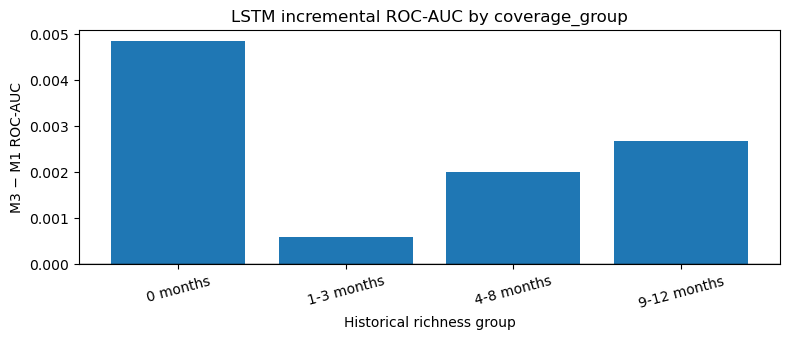

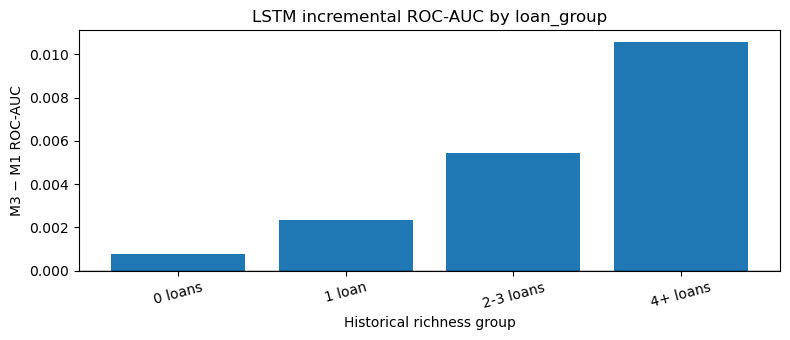

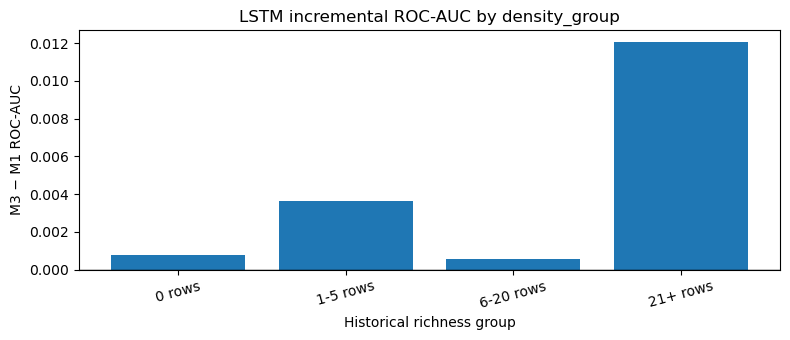

                  observed_months  distinct_loans  installment_rows
observed_months          1.000000        0.527866          0.631065
distinct_loans           0.527866        1.000000          0.875234
installment_rows         0.631065        0.875234          1.000000


In [60]:
for dimension in ['coverage_group','loan_group','density_group']:
    s=subgroup_results[subgroup_results.dimension==dimension]
    fig,ax=plt.subplots(figsize=(8,3.5))
    ax.bar(s.group.astype(str),s.delta_auc_M3_minus_M1)
    ax.axhline(0,color='black',linewidth=1)
    ax.set(title=f'LSTM incremental ROC-AUC by {dimension}',ylabel='M3 − M1 ROC-AUC',xlabel='Historical richness group')
    plt.xticks(rotation=15);plt.tight_layout();plt.show()

# Examine correlations to understand how the three richness measures overlap.
print(richness[['observed_months','distinct_loans','installment_rows']].corr(method='spearman'))

## 11 · Richness-aware fusion (exploratory, disjoint calibration/evaluation)

**Why:** A customer with no repayment history cannot provide a meaningful individualized LSTM sequence; sparse and dense histories may warrant different weighting. We compare three ways of combining the **already-fitted M1 GBDT** and the **OOF-trained LSTM ensemble**:

- **M1 only**: no LSTM score.
- **Fixed blend**: one learned global weight, fitted on calibration-only data.
- **Richness-aware blend**: a small regularized logistic model using *logit(M1), logit(LSTM), three log-scaled richness measures, and score x richness interactions*.

**Important:** The M1 GBDT and LSTM are trained on `train`, not `val`. We split `val` into `calibration` and `evaluation` (stratified). Blend parameters are selected on calibration only; evaluation is disjoint. This reduces evaluation sample size and is **not** directly comparable with full-validation M0-M3 results.

In [61]:
from sklearn.linear_model import LogisticRegression
from scipy.special import logit, expit

p_gbdt=np.asarray(val_predictions['M1'],dtype=float)
p_lstm=np.asarray(lstm_score[val_idx],dtype=float)
y_val=y[val_idx]
cal_pos,eval_pos=train_test_split(np.arange(len(val_idx)),test_size=0.5,
                                   stratify=y_val,random_state=SEED+202)

def cliplogit(p):return logit(np.clip(p,1e-5,1-1e-5))

# Static convex blend: choose weight using calibration-only AUC, no evaluation peeking.
blend_grid=np.linspace(0,0.5,21)
cal_auc=[safe_auc(y_val[cal_pos],(1-w)*p_gbdt[cal_pos]+w*p_lstm[cal_pos]) for w in blend_grid]
best_weight=float(blend_grid[int(np.nanargmax(cal_auc))])
p_fixed=(1-best_weight)*p_gbdt+best_weight*p_lstm

# Compact gated model: scores + richness + score-by-richness interactions.
R=np.column_stack([np.log1p(months[val_idx]),np.log1p(loan_n[val_idx]),np.log1p(event_n[val_idx])])
Rsc=StandardScaler().fit(R[cal_pos]);Rz=Rsc.transform(R)
g=cliplogit(p_gbdt);l=cliplogit(p_lstm)
# Relative-score interactions permit data-driven reliance on LSTM as richness varies.
diff=l-g
Z=np.column_stack([g,l,Rz,diff[:,None]*Rz])
gate=LogisticRegression(C=0.1,max_iter=2000,random_state=SEED)
gate.fit(Z[cal_pos],y_val[cal_pos])
p_gated=gate.predict_proba(Z)[:,1]

rows=[]
for name,p in [('M1 (no LSTM)',p_gbdt),('Fixed score blend',p_fixed),
               ('Richness-aware logistic fusion',p_gated)]:
    rows.append({'method':name,'calibration_auc':safe_auc(y_val[cal_pos],p[cal_pos]),
                 'evaluation_auc':safe_auc(y_val[eval_pos],p[eval_pos]),
                 'evaluation_pr_auc':safe_ap(y_val[eval_pos],p[eval_pos]),
                 'evaluation_n':len(eval_pos),'evaluation_positives':int(y_val[eval_pos].sum())})
gated_results=pd.DataFrame(rows)
print('Calibration-selected fixed blend LSTM weight:',best_weight)
display(gated_results)
gated_results.to_csv(OUTPUT_DIR/'richness_aware_fusion_v6.csv',index=False)

Calibration-selected fixed blend LSTM weight: 0.025


,method,calibration_auc,evaluation_auc,evaluation_pr_auc,evaluation_n,evaluation_positives
0,M1 (no LSTM),0.755013,0.772034,0.253986,7501,606
1,Fixed score blend,0.755204,0.773239,0.254364,7501,606
2,Richness-aware logistic fusion,0.759592,0.771242,0.254142,7501,606


### 11.1 · Where does conditional fusion help?

This subgroup analysis uses **evaluation-only** observations, never calibration examples. Small subgroups have noisy AUC; treat differences as exploratory.

In [62]:
conditional_rows=[]
for dimension in ['coverage_group','loan_group','density_group']:
    for group in val_meta[dimension].cat.categories:
        mask=(val_meta[dimension].astype(str).to_numpy()==str(group))
        keep=np.intersect1d(np.flatnonzero(mask),eval_pos)
        if len(keep)==0:continue
        yt=y_val[keep]
        conditional_rows.append({'dimension':dimension,'group':str(group),'n':len(keep),
          'positives':int(yt.sum()),'M1_auc':safe_auc(yt,p_gbdt[keep]),
          'fixed_auc':safe_auc(yt,p_fixed[keep]),'gated_auc':safe_auc(yt,p_gated[keep]),
          'gated_delta_auc':safe_auc(yt,p_gated[keep])-safe_auc(yt,p_gbdt[keep])})
conditional_results=pd.DataFrame(conditional_rows)
display(conditional_results)
conditional_results.to_csv(OUTPUT_DIR/'richness_aware_subgroups_v6.csv',index=False)

,dimension,group,n,positives,M1_auc,fixed_auc,gated_auc,gated_delta_auc
0,coverage_group,0 months,1450,113,0.758368,0.758368,0.758368,0.000000
1,coverage_group,1-3 months,296,30,0.731203,0.730952,0.727694,-0.003509
2,coverage_group,4-8 months,1015,81,0.767798,0.767944,0.766873,-0.000925
3,coverage_group,9-12 months,4740,382,0.779865,0.781436,0.780862,0.000997
4,loan_group,0 loans,2194,169,0.767913,0.768220,0.761885,-0.006028
5,loan_group,1 loan,3112,254,0.774006,0.775850,0.774079,0.000073
6,loan_group,2-3 loans,2039,167,0.779185,0.780884,0.783356,0.004171
7,loan_group,4+ loans,156,16,0.707589,0.707589,0.714286,0.006696
8,density_group,0 rows,2194,169,0.767913,0.768220,0.761885,-0.006028
9,density_group,1-5 rows,1111,87,0.777680,0.777737,0.774470,-0.003210


## 12 · Optional bootstrap uncertainty for paired AUC differences

Resample **the same evaluation applicants** for M1 and gated fusion. This measures sampling uncertainty conditional on the fitted models and does not account for training-seed variability. Do not treat overlapping/zero-crossing intervals as definitive proof of no effect.

In [63]:
RUN_BOOTSTRAP=True
if RUN_BOOTSTRAP:
    rng=np.random.default_rng(SEED+303)
    diffs=[]
    for _ in range(500):
        sample=rng.choice(eval_pos,size=len(eval_pos),replace=True)
        if np.unique(y_val[sample]).size<2:continue
        diffs.append(roc_auc_score(y_val[sample],p_gated[sample])-
                     roc_auc_score(y_val[sample],p_gbdt[sample]))
    print('Evaluation-only gated − M1 ΔAUC: ',
          round(float(np.mean(diffs)),5),' bootstrap 95% percentile interval:',
          np.round(np.percentile(diffs,[2.5,97.5]),5))

Evaluation-only gated − M1 ΔAUC:  -0.00067  bootstrap 95% percentile interval: [-0.004    0.00298]


## 13 · Interpretation guide

1. **First verify M0 parity** against the teammate's All Sources run. Matching model parameters alone does not guarantee identical features/preprocessing.
2. **Primary result**: M3 vs M1 on full validation. If LSTM hurts, report it.
3. **Richness**: report sample counts, positives, subgroup default rates, and AUC deltas for coverage, loan breadth and density. Do not infer a monotonic benefit without evidence.
4. **Conditional fusion**: compare methods on the **same held-out evaluation half** only. Calibration AUC is optimistic and is not the headline metric.
5. **Leakage audit**: cleaned installment rows may include future payment totals for installments due before application. Verify `installments.parquet` construction and payment-time availability before interpreting results as deployable. For strict point-in-time correctness, reconstruct from payment events with timestamps and censor payments after application date.
6. **Test**: keep locked until model and calibration choices are frozen. For a gated model, final test scoring requires constructing test richness features, score predictions and applying a frozen gate; the existing optional test cell below covers M0–M3 only.

## 14 · Optional held-out test — **only after freezing model selection**

The default is `RUN_FINAL_TEST=False` to prevent accidental repeated test-set evaluation. Do not use test metrics to tune architecture, fusion, or feature selection. For an unbiased final evaluation, train the chosen GBDT on the training split only and evaluate the untouched test split. (For deployment/refitting on train+val, regenerate all cross-fitted neural features consistently.)

In [64]:
RUN_FINAL_TEST=False
SELECTED_MODEL='M3'
if RUN_FINAL_TEST:
    assert SELECTED_MODEL in feature_sets
    X=feature_sets[SELECTED_MODEL]
    model=fitted_models[SELECTED_MODEL]
    p=model.predict_proba(X.iloc[test_idx])[:,1]
    print({'model':SELECTED_MODEL,'test_auc':roc_auc_score(y[test_idx],p),
           'test_pr_auc':average_precision_score(y[test_idx],p)})
else:
    print('Test locked. Set RUN_FINAL_TEST=True only once after model selection.')

Test locked. Set RUN_FINAL_TEST=True only once after model selection.


## Interpretation and limitations

- **Additive chain design:** M_app -> M0 -> M1 -> M2 -> M3. Each step adds exactly one ingredient on top of M0 (the Exp 1 baseline), isolating its marginal contribution.
- **Primary claim:** incremental validation performance of M1 and M2 over M0, and whether the full M3 exceeds either alone.
- **V6 improvements:** weighted BCE loss, last-hidden OOF pooling, 14 multi-source handcrafted temporal features, bureau balance flat aggregates in GBDT.
- **M_app baseline:** Shows the value of all historical data; the gap M_app -> M0 is the historical contribution to the GBDT.
- **If no lift:** report that the tested LSTM representation was not complementary; avoid cherry-picking a favorable seed.
- **Baseline parity:** compare M0 to your teammate's Exp 1 output. Same hyperparameters are necessary but not sufficient.
- **OOF caveat:** training scores come from fold models, while val/test scores are multi-model averages; their noise levels differ.
- **Leakage audit:** cleaned installment rows may include future payment totals. Bureau balance uses `MONTHS_BALANCE` which is relative to application, so no temporal leakage.
- **Compute:** the notebook trains 3 OOF LSTMs (2-layer, hidden=64) plus standalone/ablation models; GPU recommended.